## Import Libraries

In [313]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import (mean_squared_error, r2_score, mean_absolute_error)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


* These libraries provide tools for data handling, visualization, splitting data, building regression models, and evaluating predictions.

## Load  Dataset

In [314]:
df = pd.read_csv("RealEstate_HousePrice_Dataset.csv")
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


* This loads the house-price dataset into a DataFrame and displays the first few rows so you can preview the data.

## Explore Dataset Structure and Summary Statistics

In [315]:
df.info()
df.describe()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   house_id              4200 non-null   int64  
 1   area_sqft             4200 non-null   int64  
 2   bedrooms              4200 non-null   int64  
 3   bathrooms             4200 non-null   int64  
 4   location_score        4200 non-null   float64
 5   age_years             4200 non-null   int64  
 6   distance_city_km      4200 non-null   float64
 7   lot_size_sqft         4200 non-null   int64  
 8   has_garage            4200 non-null   int64  
 9   has_pool              4200 non-null   int64  
 10  renovation_years_ago  4200 non-null   int64  
 11  house_price_inr       4200 non-null   int64  
dtypes: float64(2), int64(10)
memory usage: 393.9 KB


Index(['house_id', 'area_sqft', 'bedrooms', 'bathrooms', 'location_score',
       'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage',
       'has_pool', 'renovation_years_ago', 'house_price_inr'],
      dtype='object')

* These commands show the dataset structure, summary statistics, and column names to help you understand the available data.

## Check Missing Values and Duplicate Rows

In [316]:
df.isnull().sum()
df.duplicated().sum()

0

* This checks missing values and duplicate rows so you can identify basic data-quality issues.

## Identify Independent and Dependent Variables

In [317]:
X = df.drop(["house_id", "house_price_inr"], axis=1)
y = df["house_price_inr"]

print(X.head())
print(y.head())

   area_sqft  bedrooms  bathrooms  location_score  age_years  \
0       1973         5          4             7.6         23   
1       1560         3          3             6.3         13   
2       2071         4          3             5.8          9   
3       2640         5          3             7.7         12   
4       1498         3          3             3.8         15   

   distance_city_km  lot_size_sqft  has_garage  has_pool  renovation_years_ago  
0              11.9           5220           1         0                     0  
1              15.8           3882           1         0                    13  
2              21.1           4488           0         0                     9  
3               7.9           3614           1         1                     4  
4              24.0           2663           0         0                    15  
0    40275084
1    26812029
2    29315677
3    47712959
4    17724566
Name: house_price_inr, dtype: int64


* X contains the input features, while y contains the house price that the model will learn to predict.

## Visualize Area vs House Price

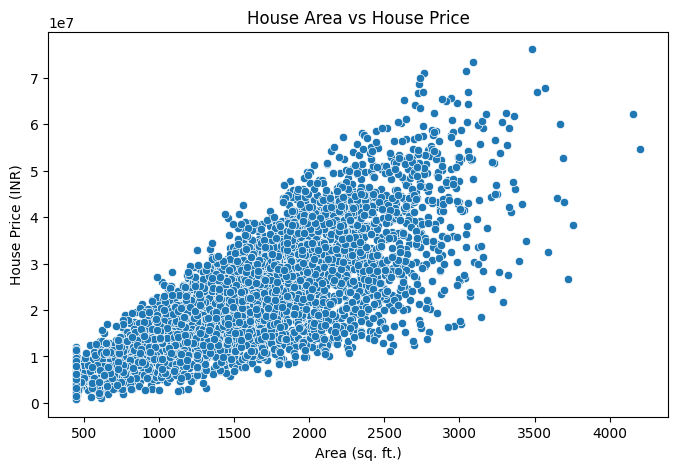

In [318]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="area_sqft",
    y="house_price_inr"
)

plt.title("House Area vs House Price")
plt.xlabel("Area (sq. ft.)")
plt.ylabel("House Price (INR)")
plt.show()

* The scatter plot helps you see whether larger houses tend to have higher prices and whether the relationship looks linear.

## Compare House Prices by Number of Bedrooms

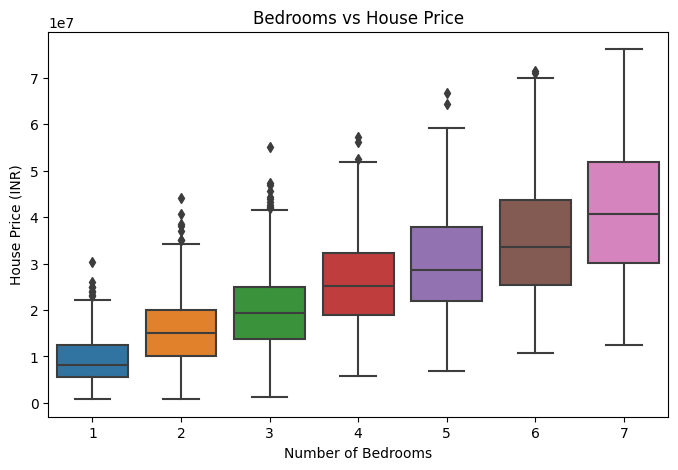

In [319]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="bedrooms",
    y="house_price_inr"
)

plt.title("Bedrooms vs House Price")
plt.xlabel("Number of Bedrooms")
plt.ylabel("House Price (INR)")
plt.show()

* The box plot compares house-price distributions for different bedroom counts and highlights spread and possible outliers.

## Visualize Feature Correlations

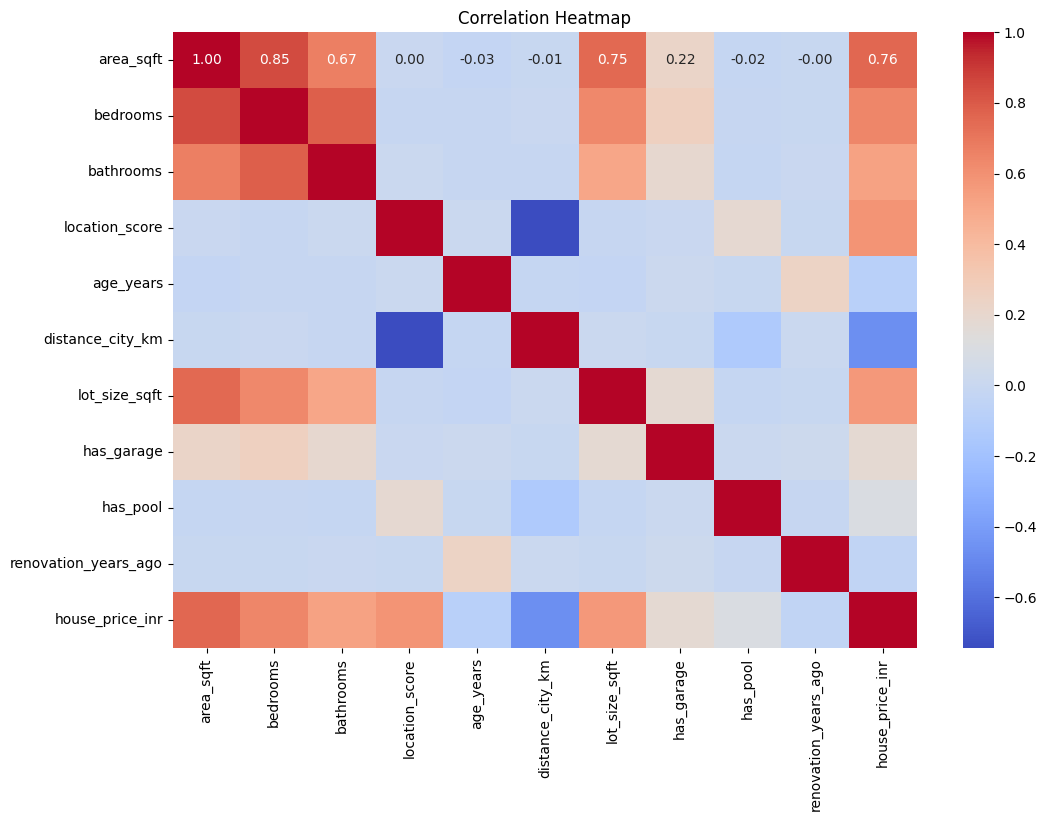

In [320]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.drop(columns=["house_id"]).corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

* The heatmap shows correlations between numerical variables, helping you spot features that move together with house price.

## Split Data into Training and Testing Sets

In [321]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(3360, 10)
(840, 10)
(3360,)
(840,)


* The data is split into 80% for training and 20% for testing so the model can be evaluated on unseen examples.

## Review Input Features and Target Variable

In [322]:
X = df.drop(columns=["house_id","house_price_inr"])
y =df["house_price_inr"]

print("Independent Variables:")
print(X.head())

print("\n\nDependent Variable:")
print(y.head())

Independent Variables:
   area_sqft  bedrooms  bathrooms  location_score  age_years  \
0       1973         5          4             7.6         23   
1       1560         3          3             6.3         13   
2       2071         4          3             5.8          9   
3       2640         5          3             7.7         12   
4       1498         3          3             3.8         15   

   distance_city_km  lot_size_sqft  has_garage  has_pool  renovation_years_ago  
0              11.9           5220           1         0                     0  
1              15.8           3882           1         0                    13  
2              21.1           4488           0         0                     9  
3               7.9           3614           1         1                     4  
4              24.0           2663           0         0                    15  


Dependent Variable:
0    40275084
1    26812029
2    29315677
3    47712959
4    17724566
Name: house_pr

* This prints the independent features and the target price separately to confirm which data is used for prediction.

## Train Simple Linear Regression

In [323]:
X = df[["area_sqft"]]
y = df["house_price_inr"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Model training completed!")

Training data: (3360, 1)
Testing data: (840, 1)
Model training completed!


* This trains a Simple Linear Regression model using only house area to predict house price.

## Plot the Regression Line and Interpret Coefficients

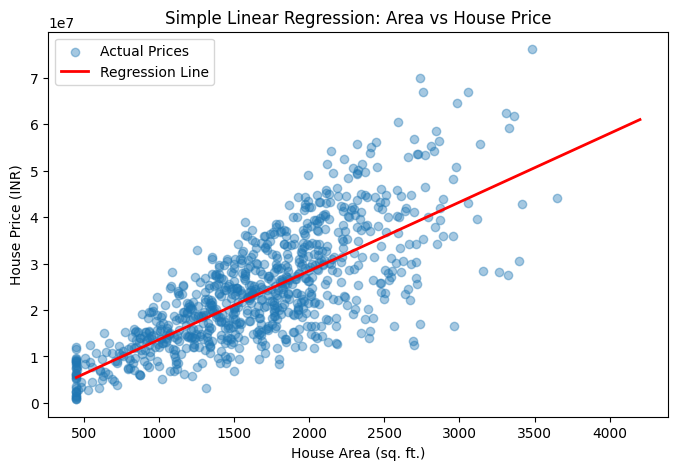

Slope: 14788.306111307533
Intercept: -1163519.1764185987


In [324]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test["area_sqft"], y_test, alpha=0.4,
            label="Actual Prices")

X_line = pd.DataFrame({
    "area_sqft": np.linspace(
        df["area_sqft"].min(),
        df["area_sqft"].max(),
        200
    )
})

y_line = model.predict(X_line)


plt.plot(X_line["area_sqft"], y_line,
         color="red", linewidth=2,
         label="Regression Line")

plt.xlabel("House Area (sq. ft.)")
plt.ylabel("House Price (INR)")
plt.title("Simple Linear Regression: Area vs House Price")
plt.legend()
plt.show()

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

* The plot compares actual prices with the fitted regression line; slope shows the estimated price change per extra square foot, and intercept is the predicted price at zero area.

## Analyze Regression Residuals

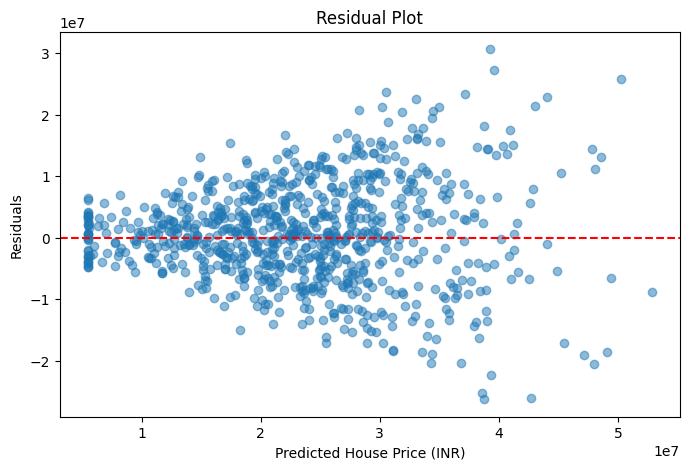

In [325]:
y_pred = model.predict(X_test)


residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted House Price (INR)")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


* Residuals are actual prices minus predicted prices. A random spread around zero is generally a good sign; clear patterns may indicate the linear model is missing something.

## Evaluate Simple Linear Regression

In [326]:
y_pred = model.predict(X_test)


mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


n = X_test.shape[0]       
p = X_test.shape[1]       

if n > p + 1:
    adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
else:
    adjusted_r2 = float("nan")


print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)
print("Adjusted R² Score:", adjusted_r2)

Mean Squared Error (MSE): 66989260021849.47
Mean Absolute Error (MAE): 6294593.696131912
Root Mean Squared Error (RMSE): 8184696.696997969
R² Score: 0.5625199587991578
Adjusted R² Score: 0.5619979062440257


* These metrics summarize prediction errors and model fit. Lower MSE, MAE, and RMSE are better; an R² closer to 1 generally indicates a better fit.

## Train Multiple Linear Regression

In [327]:
X_multi = df.drop(columns=["house_id", "house_price_inr"])
y_multi = df["house_price_inr"]

X_multi = pd.get_dummies(X_multi, drop_first=True, dtype=int)

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi, test_size=0.20, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train_multi, y_train_multi)

y_pred_multi = multi_model.predict(X_test_multi)

print("Multiple Linear Regression model trained successfully!")
print("Number of features:", X_multi.shape[1])

Multiple Linear Regression model trained successfully!
Number of features: 10


* This trains Multiple Linear Regression using all available features, after converting categorical columns into numeric indicator columns where needed.

## Compare Simple and Multiple Linear Regression

In [328]:
X_simple = df[["area_sqft"]]

X_train_simple = X_simple.loc[X_train_multi.index]
X_test_simple = X_simple.loc[X_test_multi.index]

simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train_multi)

y_pred_simple = simple_model.predict(X_test_simple)

def evaluate_model(y_true, y_pred, number_of_features):
    n = len(y_true)
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    if n > number_of_features + 1:
        adjusted_r2 = 1 - (
            (1 - r2) * (n - 1) / (n - number_of_features - 1)
        )
    else:
        adjusted_r2 = np.nan

    return [mse, mae, rmse, r2, adjusted_r2]


simple_results = evaluate_model(
    y_test_multi, y_pred_simple, X_simple.shape[1]
)

multiple_results = evaluate_model(
    y_test_multi, y_pred_multi, X_multi.shape[1]
)


comparison = pd.DataFrame(
    [simple_results, multiple_results],
    index=["Simple Linear Regression", "Multiple Linear Regression"],
    columns=["MSE", "MAE", "RMSE", "R2 Score", "Adjusted R2"]
)

comparison

,MSE,MAE,RMSE,R2 Score,Adjusted R2
Simple Linear Regression,6.698926e+13,6.294594e+06,8.184697e+06,0.562520,0.561998
Multiple Linear Regression,1.259292e+13,2.604991e+06,3.548650e+06,0.917761,0.916769


* This compares a one-feature model with a multiple-feature model on the same test rows. Lower error and higher R² indicate better test performance.

 ##  Train Polynomial Regression

In [329]:
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_train, y_train)
y_pred_poly = poly_model.predict(X_test)

print("Polynomial Regression (Degree 2) trained successfully!")

Polynomial Regression (Degree 2) trained successfully!


* Polynomial Regression adds a squared area term, allowing the model to learn a curved relationship instead of only a straight line.

## Compare Linear and Polynomial Regression Metrics

In [330]:
comparison = pd.DataFrame({
    "Metric": ["MSE", "MAE", "RMSE", "R2 Score"],
    "Linear Regression": [
        mean_squared_error(y_test, y_pred_linear),
        mean_absolute_error(y_test, y_pred_linear),
        np.sqrt(mean_squared_error(y_test, y_pred_linear)),
        r2_score(y_test, y_pred_linear)
    ],
    "Polynomial Regression": [
        mean_squared_error(y_test, y_pred_poly),
        mean_absolute_error(y_test, y_pred_poly),
        np.sqrt(mean_squared_error(y_test, y_pred_poly)),
        r2_score(y_test, y_pred_poly)
    ]
})

comparison

,Metric,Linear Regression,Polynomial Regression
0,MSE,6.698926e+13,6.696295e+13
1,MAE,6.294594e+06,6.292395e+06
2,RMSE,8.184697e+06,8.183089e+06
3,R2 Score,5.625200e-01,5.626918e-01


* This table compares linear and polynomial predictions using the same error metrics, helping you see whether the curve improves test performance.

## Visualize Linear and Polynomial Regression Curves

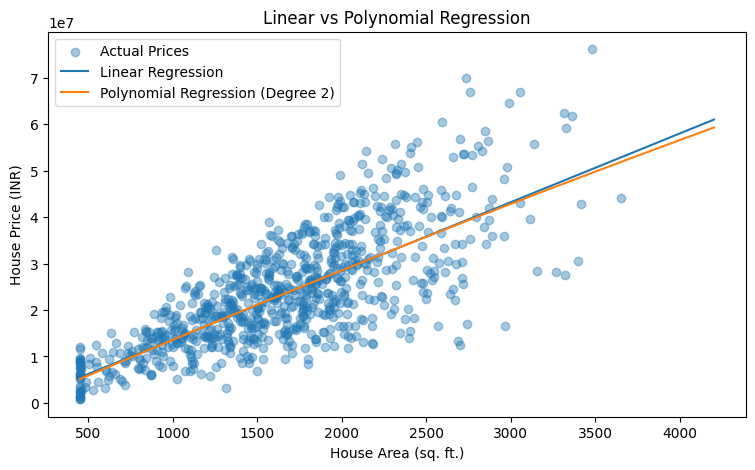

In [331]:
X_line = pd.DataFrame({
    "area_sqft": np.linspace(
        X["area_sqft"].min(),
        X["area_sqft"].max(),
        200
    )
})

plt.figure(figsize=(9, 5))

plt.scatter(X_test["area_sqft"], y_test, alpha=0.4, label="Actual Prices")

plt.plot(
    X_line["area_sqft"],
    linear_model.predict(X_line),
    label="Linear Regression"
)

plt.plot(
    X_line["area_sqft"],
    poly_model.predict(X_line),
    label="Polynomial Regression (Degree 2)"
)

plt.xlabel("House Area (sq. ft.)")
plt.ylabel("House Price (INR)")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

* This graph overlays actual prices and the fitted linear and polynomial curves so you can visually compare their shapes and fit.

## Compare Training and Testing Performance

In [332]:
y_train_linear_pred = linear_model.predict(X_train)
y_train_poly_pred = poly_model.predict(X_train)

print("Linear Regression")
print("Training R2:", r2_score(y_train, y_train_linear_pred))
print("Testing R2:", r2_score(y_test, y_pred_linear))

print("\nPolynomial Regression")
print("Training R2:", r2_score(y_train, y_train_poly_pred))
print("Testing R2:", r2_score(y_test, y_pred_poly))

Linear Regression
Training R2: 0.5723074839148459
Testing R2: 0.5625199587991578

Polynomial Regression
Training R2: 0.5724674245504779
Testing R2: 0.5626917978136458


* Comparing training and testing R² helps show how well each model fits the training data and how well it generalizes to unseen data.

## Check for Overfitting and Underfitting

In [333]:
linear_train_r2 = r2_score(y_train, y_train_linear_pred)
linear_test_r2 = r2_score(y_test, y_pred_linear)

poly_train_r2 = r2_score(y_train, y_train_poly_pred)
poly_test_r2 = r2_score(y_test, y_pred_poly)

print("Interpretation:")

if poly_train_r2 > linear_train_r2 and poly_test_r2 > linear_test_r2:
    print("Polynomial Regression fits the training data better and also improves test performance.")
elif poly_train_r2 > poly_test_r2 + 0.10:
    print("Polynomial Regression may be overfitting because training performance is much better than testing performance.")
elif linear_train_r2 < 0.5 and linear_test_r2 < 0.5:
    print("Linear Regression may be underfitting. Check whether the relationship is non-linear.")
else:
    print("Compare training and testing scores to assess overfitting or underfitting.")

Interpretation:
Polynomial Regression fits the training data better and also improves test performance.


* Polynomial Regression fits the training data better and also improves test performance.
A much stronger training score than test score can suggest overfitting; weak scores on both sets can suggest underfitting. Use the actual scores to decide.

## Implement Batch Gradient Descent

In [334]:
def batch_gd(X, y, lr=0.01, epochs=100):
    m, n = X.shape
    w = np.zeros(n)
    b = 0
    losses = []

    for _ in range(epochs):
        y_pred = X @ w + b
        error = y_pred - y

        w -= lr * (2/m) * (X.T @ error)
        b -= lr * (2/m) * np.sum(error)

        losses.append(np.mean(error**2))

    return w, b, losses

* Batch Gradient Descent updates the model using the whole training set each step, aiming to reduce the mean squared error gradually.

## Implement Stochastic Gradient Descent

In [335]:

def stochastic_gd(X, y, lr=0.01, epochs=100):
    m, n = X.shape
    w = np.zeros(n)
    b = 0
    losses = []

    for _ in range(epochs):
        for i in np.random.permutation(m):
            error = (X[i] @ w + b) - y[i]

            w -= lr * 2 * X[i] * error
            b -= lr * 2 * error

        losses.append(np.mean((X @ w + b - y)**2))

    return w, b, losses

* Stochastic Gradient Descent updates the parameters one example at a time, making updates frequent but usually noisier.

## Implement Mini-Batch Gradient Descent

In [336]:

def mini_batch_gd(X, y, lr=0.01, epochs=100, batch_size=32):
    m, n = X.shape
    w = np.zeros(n)
    b = 0
    losses = []

    for _ in range(epochs):
        indices = np.random.permutation(m)

        for start in range(0, m, batch_size):
            batch = indices[start:start + batch_size]
            Xb, yb = X[batch], y[batch]

            error = Xb @ w + b - yb
            size = len(batch)

            w -= lr * (2/size) * (Xb.T @ error)
            b -= lr * (2/size) * np.sum(error)

        losses.append(np.mean((X @ w + b - y)**2))

    return w, b, losses

* Mini-Batch Gradient Descent updates the parameters using small groups of examples, balancing update speed and stability.

## Compare Gradient Descent Convergence and Training Time

Batch GD | Final Loss: 0.438 | Time: 0.0035 seconds
Stochastic GD | Final Loss: 0.433 | Time: 1.4365 seconds
Mini-Batch GD | Final Loss: 0.4276 | Time: 0.1 seconds


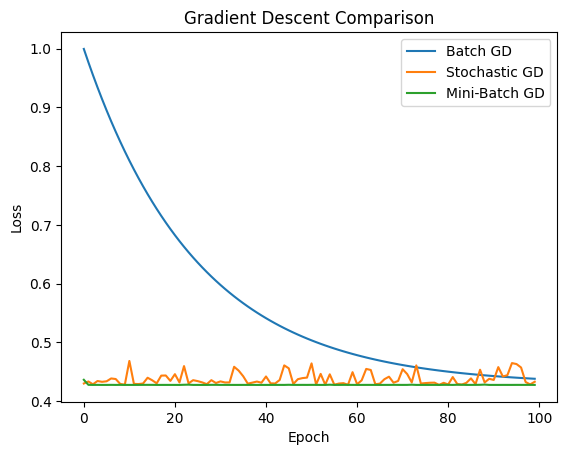

In [337]:
X = np.asarray(X_train_scaled)
y = np.asarray(y_train_scaled).ravel()

methods = {
    "Batch GD": batch_gd,
    "Stochastic GD": stochastic_gd,
    "Mini-Batch GD": mini_batch_gd
}

results = {}

for name, method in methods.items():
    start = time.time()

    w, b, loss = method(X, y)

    elapsed = time.time() - start
    results[name] = loss

    print(name, "| Final Loss:", round(loss[-1], 4),
          "| Time:", round(elapsed, 4), "seconds")

for name, loss in results.items():
    plt.plot(loss, label=name)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Gradient Descent Comparison")
plt.legend()
plt.show()

* This runs all three Gradient Descent methods, records their loss and training time, and plots loss across epochs to compare convergence.

## Prepare Models for Bias–Variance Analysis

In [338]:
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly_model.fit(X_train, y_train)


X_multi = pd.get_dummies(
    df.drop(columns=["house_id", "house_price_inr"]),
    drop_first=True,
    dtype=int
)

multiple_model = LinearRegression()
multiple_model.fit(X_train_multi, y_train_multi)


models = {
    "Simple Regression": (simple_model, X_train, X_test, y_train, y_test),
    "Multiple Regression": (
        multiple_model, X_train_multi, X_test_multi,
        y_train_multi, y_test_multi
    ),
    "Polynomial Regression": (poly_model, X_train, X_test, y_train, y_test)
}

for name, (model, Xtr, Xte, ytr, yte) in models.items():
    print("\n", name)
    print("Training R2:", round(model.score(Xtr, ytr), 3))
    print("Testing R2:", round(model.score(Xte, yte), 3))


 Simple Regression
Training R2: 0.572
Testing R2: 0.563

 Multiple Regression
Training R2: 0.925
Testing R2: 0.918

 Polynomial Regression
Training R2: 0.572
Testing R2: 0.563


* This trains simple, multiple, and polynomial regression models so their training and testing R² scores can be compared.

## Compare Training and Testing R² Scores

In [339]:
for name, (model, Xtr, Xte, ytr, yte) in models.items():
    train_r2 = model.score(Xtr, ytr)
    test_r2 = model.score(Xte, yte)

    print(name, "| Train R2:", round(train_r2, 3),
          "| Test R2:", round(test_r2, 3))

Simple Regression | Train R2: 0.572 | Test R2: 0.563
Multiple Regression | Train R2: 0.925 | Test R2: 0.918
Polynomial Regression | Train R2: 0.572 | Test R2: 0.563


* This prints the training and testing R² scores for each model. A large gap may be a warning sign of overfitting

## Compare Final Model Evaluation Metrics

In [340]:

for name, (model, Xtr, Xte, ytr, yte) in models.items():
    y_pred = model.predict(Xte)

    mse = mean_squared_error(yte, y_pred)
    mae = mean_absolute_error(yte, y_pred)
    rmse = np.sqrt(mse)
    r2 = model.score(Xte, yte)

    print("\nModel:", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 3))


Model: Simple Regression
MAE: 6294593.7
RMSE: 8184696.7
R2 Score: 0.563

Model: Multiple Regression
MAE: 2604991.41
RMSE: 3548650.29
R2 Score: 0.918

Model: Polynomial Regression
MAE: 6292394.56
RMSE: 8183089.09
R2 Score: 0.563


* This compares the models using test-set MAE, RMSE, and R² so you can judge prediction accuracy and overall fit.